# Module 1 - Fundamentals, colour spaces and digital enhancement

**Goal.** Understand the matrix representation of an image `F(x, y) = I`, assess spatial and amplitude resolution,
reduce noise and improve contrast in the spatial and in the frequency domain.

Everything is driven by `config.yaml` (video, frame times, ROI and every parameter used below).
The processing functions live in `src/psib/`; this notebook only calls them and shows the results.

| Section | Content |
|---|---|
| 1.0 | Frame extraction and ROI |
| 1.1 | Sampling, quantisation, colour spaces |
| 1.2 | Histogram, brightness/contrast, equalisation, noise and spatial filtering |
| 1.3 | Edge detection, 2-D DFT, PSD, frequency-domain filtering |
| 1.4 | Quality metrics (PSNR / SSIM) summary |
| 1.5 | Answers to the guide questions |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "config.yaml").exists():      # notebook launched from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from psib.config import load_config
from psib import video_io as vio
from psib import roi as roi_mod
from psib import color as C
from psib import sampling as S
from psib import intensity as I
from psib import noise as N
from psib import filters as F
from psib import edges as E
from psib import frequency as Q
from psib import metrics as M
from psib.plotting import show_grid, save_fig
from psib.utils import to_uint8

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config(ROOT / "config.yaml")
m1 = cfg["module1"]
K, SIGMA = m1["filters"]["kernel"], m1["filters"]["gaussian_sigma"]

# Every PSNR/SSIM computed in this notebook is also stored here (summary in section 1.4)
metrics_rows = []

def evaluate(group, ref, variants):
    """PSNR / SSIM of each variant against ref; results are also logged for the final summary."""
    table = M.compare(ref, variants)
    for name, row in table.iterrows():
        metrics_rows.append({"group": group, "variant": name, "PSNR_dB": row["PSNR_dB"], "SSIM": row["SSIM"]})
    return table

def norm_display(x, clip_percentiles=(1, 99)):
    """Stretch an unbounded float image to uint8 for display (percentile clipping)."""
    lo, hi = np.percentile(x, clip_percentiles)
    return to_uint8(np.clip(x, lo, hi), "minmax")

def plot_hist(ax, gray, title, color="tab:blue"):
    ax.bar(np.arange(256), I.histogram(gray), width=1.0, color=color)
    ax.set_xlim(0, 255); ax.set_title(title, fontsize=10)
    ax.set_xlabel("gray level"); ax.set_ylabel("pixels")

## 1.0 Frame extraction and region of interest (ROI)

Frames are selected by **real timestamp** (the phone video is variable frame rate). `primary_time_s` is the working frame
(baseline, before the light in `A_n` records) and `secondary_time_s` is a second frame used for comparisons
(magnitude/phase swapping in 1.3). The ROI is the same box on both frames.

Video: /home/zenith/Videos/PSIB/A_2.mp4
Primary frame   : requested 1.00 s -> frame 30 at 1.000 s
Secondary frame : requested 5.00 s -> frame 179 at 5.000 s
ROI (x, y, w, h): (172, 357, 154, 109)


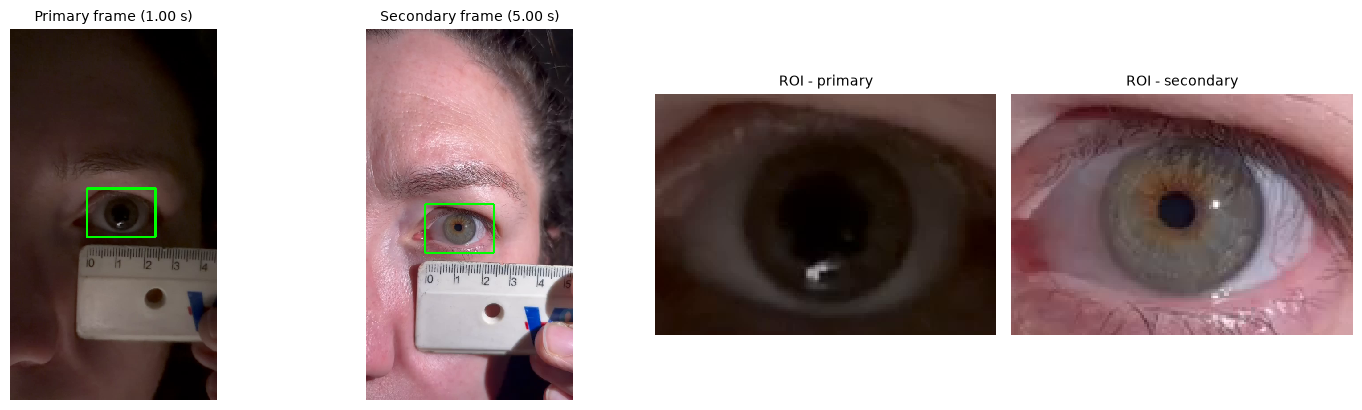

In [2]:
t1, t2 = cfg["frames"]["primary_time_s"], cfg["frames"]["secondary_time_s"]
(frame1, t1_real, idx1), (frame2, t2_real, idx2) = vio.read_frames_at_times(cfg["video_path"], [t1, t2])
print("Video:", cfg["video_path"])
print(f"Primary frame   : requested {t1:.2f} s -> frame {idx1} at {t1_real:.3f} s")
print(f"Secondary frame : requested {t2:.2f} s -> frame {idx2} at {t2_real:.3f} s")

roi = roi_mod.get_roi(cfg, frame1)          # (x, y, w, h); mode manual or interactive (see config.yaml)
print("ROI (x, y, w, h):", roi)

tracked = roi_mod.tracked_frame_rois([(frame1, t1_real, idx1), (frame2, t2_real, idx2)], roi, cfg["module3"].get("eye_tracking", {}), cfg["video_path"])
(rgb, roi1), (rgb2, roi2) = tracked
gray, gray2 = C.to_gray(rgb), C.to_gray(rgb2)

fig = show_grid([roi_mod.draw_roi(frame1, roi1), roi_mod.draw_roi(frame2, roi2), rgb, rgb2],
                [f"Primary frame ({t1_real:.2f} s)", f"Secondary frame ({t2_real:.2f} s)",
                 "ROI - primary", "ROI - secondary"], ncols=4, cell=(3.6, 4.2))
save_fig(fig, "m1_00_frames_roi", cfg); plt.show()

## 1.1 Sampling, quantisation and colour spaces

### 1.1.1 Dimensions and bit depth

In [3]:
info_full, info_roi = S.image_info(frame1), S.image_info(rgb)
display(pd.DataFrame({"full frame": info_full, "ROI": info_roi}).astype(str))
print(f"ROI: {info_roi['width']} x {info_roi['height']} (width x height), "
      f"{info_roi['channels']} channels, {info_roi['bit_depth']} bits/channel "
      f"-> {info_roi['gray_levels']} gray levels per channel")

,full frame,ROI
width,464,154
height,832,109
channels,3,3
dtype,uint8,uint8
bit_depth,8,8
gray_levels,256,256


ROI: 154 x 109 (width x height), 3 channels, 8 bits/channel -> 256 gray levels per channel


### 1.1.2 Spatial resolution: sub-sampling to 50 %, 25 % and 5 %

Area averaging is used when reducing (it behaves as an anti-aliasing low-pass). For display, every version is enlarged back with
*nearest-neighbour* so the real pixel size is visible; PSNR/SSIM are computed on the *bilinear* enlargement.

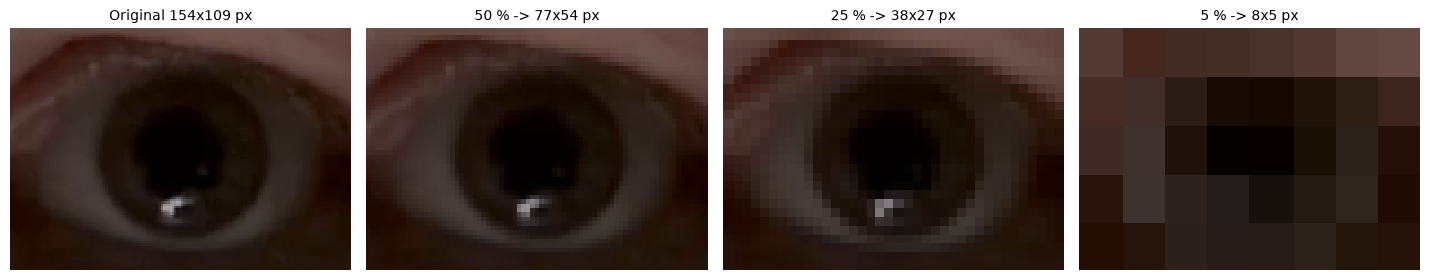

,PSNR_dB,SSIM
variant,,
50 %,42.988,0.987
25 %,36.861,0.955
5 %,26.462,0.720


In [4]:
factors = m1["downsample_factors"]
small = {f: S.downsample(rgb, f) for f in factors}
pct = lambda f: round(f * 100)

fig = show_grid([rgb] + [S.upsample_to(small[f], rgb.shape, nearest=True) for f in factors],
                [f"Original {rgb.shape[1]}x{rgb.shape[0]} px"] +
                [f"{pct(f)} % -> {small[f].shape[1]}x{small[f].shape[0]} px" for f in factors],
                ncols=len(factors) + 1, cell=(3.6, 2.8))
save_fig(fig, "m1_11_downsampling", cfg); plt.show()

evaluate("downsampling (RGB)", rgb,
         {f"{pct(f)} %": S.upsample_to(small[f], rgb.shape, nearest=False) for f in factors})

### 1.1.3 Amplitude resolution: quantisation from 8 bits to 4 and 2 bits

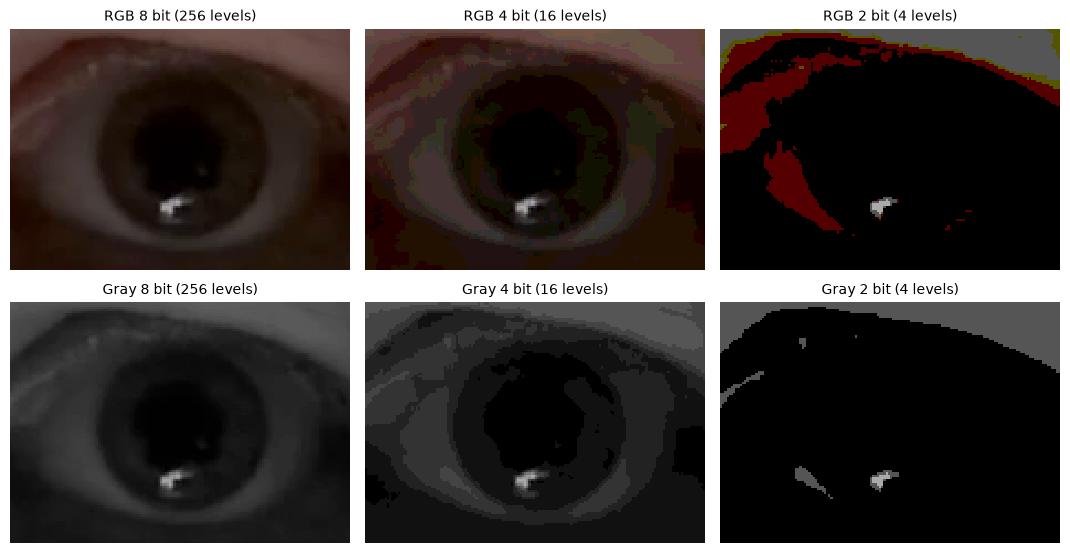

,PSNR_dB,SSIM
variant,,
RGB 4 bit,31.091,0.763
RGB 2 bit,18.283,0.159


,PSNR_dB,SSIM
variant,,
gray 4 bit,31.176,0.802
gray 2 bit,18.138,0.129


In [5]:
bits = m1["quantization_bits"]
q_rgb = {b: S.quantize(rgb, b) for b in bits}
q_gray = {b: S.quantize(gray, b) for b in bits}

fig = show_grid([rgb] + [q_rgb[b] for b in bits] + [gray] + [q_gray[b] for b in bits],
                ["RGB 8 bit (256 levels)"] + [f"RGB {b} bit ({2**b} levels)" for b in bits] +
                ["Gray 8 bit (256 levels)"] + [f"Gray {b} bit ({2**b} levels)" for b in bits],
                ncols=len(bits) + 1, cell=(3.6, 2.8))
save_fig(fig, "m1_11_quantization", cfg); plt.show()

display(evaluate("quantization (RGB)", rgb, {f"RGB {b} bit": q_rgb[b] for b in bits}))
display(evaluate("quantization (gray)", gray, {f"gray {b} bit": q_gray[b] for b in bits}))

### 1.1.4 Colour spaces: R, G, B channels and HSV

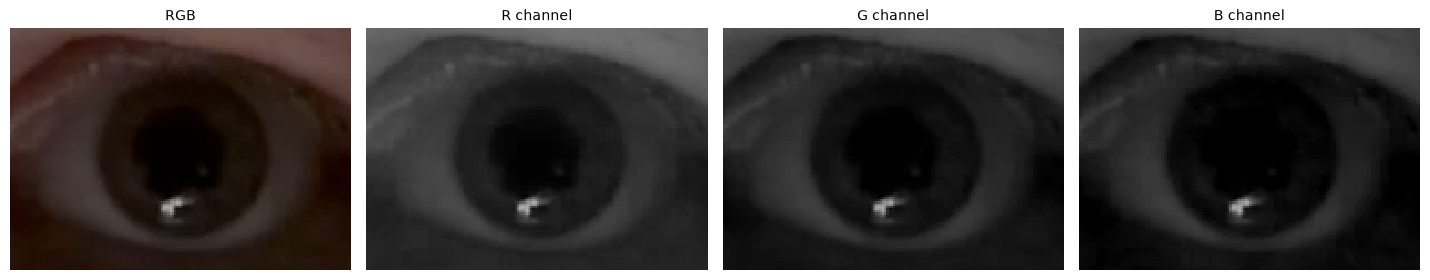

,R,G,B
mean,47.609,31.351,25.241
std,25.498,21.292,21.987


In [6]:
R_, G_, B_ = C.split_channels(rgb)
fig = show_grid([rgb, R_, G_, B_], ["RGB", "R channel", "G channel", "B channel"], ncols=4, cell=(3.6, 2.8))
save_fig(fig, "m1_11_rgb_channels", cfg); plt.show()
display(pd.DataFrame({n: {"mean": ch.mean(), "std": ch.std()} for n, ch in zip("RGB", (R_, G_, B_))}))

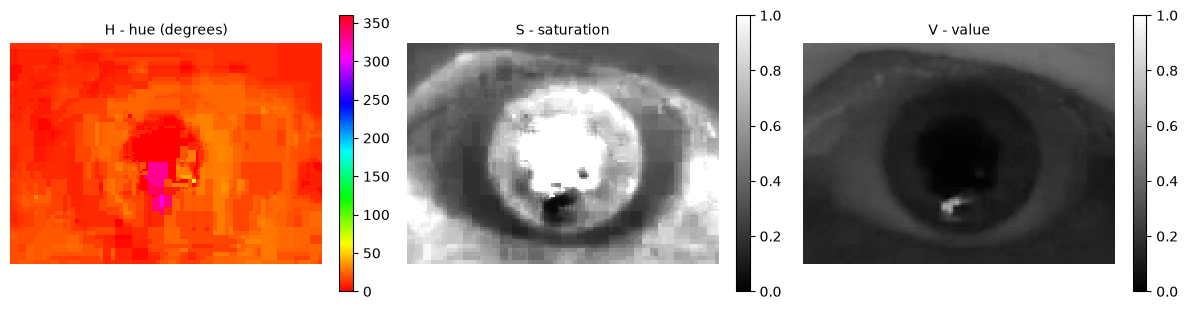

In [7]:
H, Sat, V = C.rgb_to_hsv(rgb)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, data, title, cmap, vmax in zip(axes, (H, Sat, V),
                                       ("H - hue (degrees)", "S - saturation", "V - value"),
                                       ("hsv", "gray", "gray"), (360, 1, 1)):
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); save_fig(fig, "m1_11_hsv", cfg); plt.show()

*Hue is circular (0 deg and 360 deg are both red). Videos are stored with 4:2:0 chroma subsampling (`yuv420p`), so H and S
look blockier than V, which keeps the full resolution. Check which of the three components separates pupil, iris and sclera best.*

## 1.2 Image quality, intensity transformations and spatial filtering

### 1.2.1 Histogram, brightness and contrast

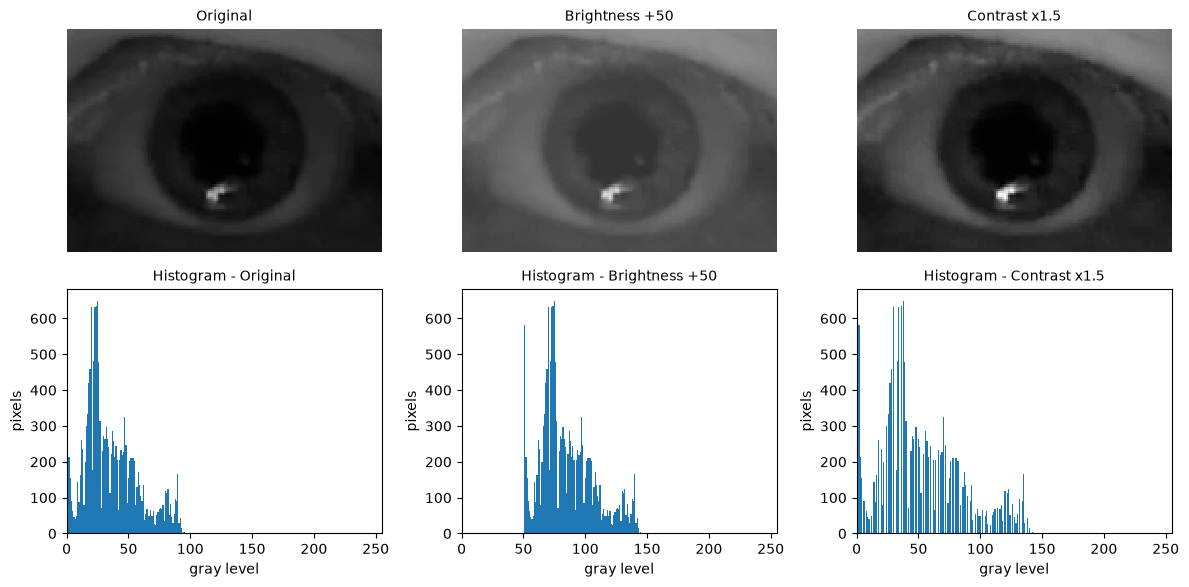

,mean,std,min,max,entropy_bits,clipped_%
Original,35.560,22.433,0.000,168.000,6.125,0.006
Brightness +50,85.560,22.433,50.000,218.000,6.125,0.000
Contrast x1.5,53.352,33.635,0.000,252.000,6.125,0.006


,PSNR_dB,SSIM
variant,,
Brightness +50,14.151,0.629
Contrast x1.5,21.675,0.893


In [8]:
bright = I.adjust_brightness(gray, m1["brightness_offset"])
contrast = I.adjust_contrast(gray, m1["contrast_factor"])
versions = {"Original": gray,
            f"Brightness {m1['brightness_offset']:+d}": bright,
            f"Contrast x{m1['contrast_factor']}": contrast}

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for col, (name, img) in enumerate(versions.items()):
    axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, col].axis("off")
    axes[0, col].set_title(name, fontsize=10)
    plot_hist(axes[1, col], img, f"Histogram - {name}")
fig.tight_layout(); save_fig(fig, "m1_12_brightness_contrast", cfg); plt.show()

display(pd.DataFrame({k: M.describe(v) for k, v in versions.items()}).T)
display(evaluate("brightness / contrast", gray, {k: v for k, v in versions.items() if k != "Original"}))

*Look at: the brightness offset shifts the whole histogram to the right (same shape, same std) and piles pixels at 255 if the
original had bright values; the contrast factor stretches the histogram (larger std, gaps between bins) and saturates the top.
`clipped_%` quantifies the information destroyed by saturation.*

### 1.2.2 Linear scaling on an intensity range of interest `[f1, f2]`

`f1` and `f2` are taken as percentiles of the gray ROI (`range_percentiles` in `config.yaml`): the low percentiles contain the
pupil and the iris; the bright sclera / skin are deliberately saturated.

Range of interest: f1 = 1, f2 = 37  (percentiles 1-60)


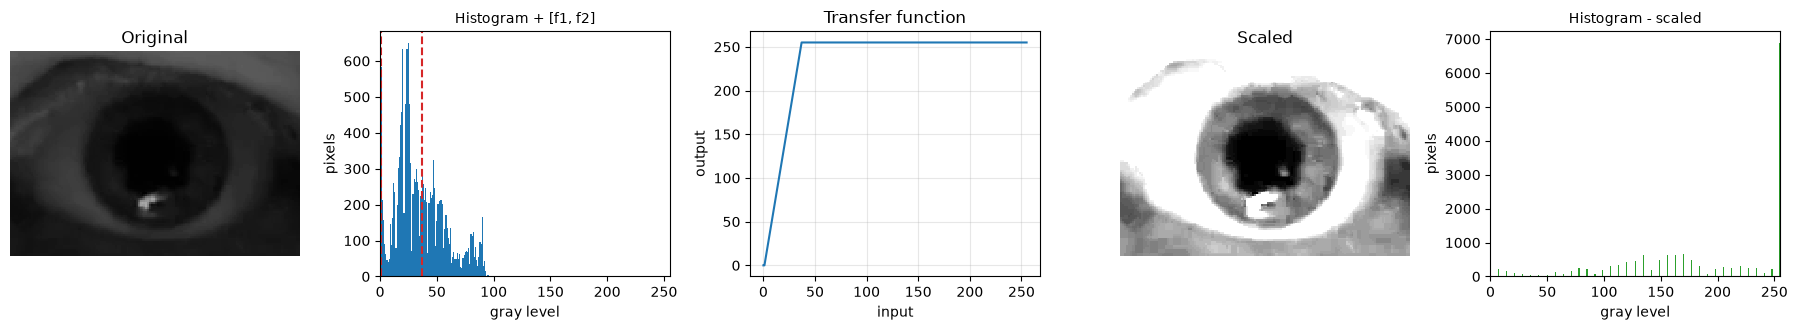

In [9]:
p_lo, p_hi = m1["range_percentiles"]
f1, f2 = I.percentile_range(gray, p_lo, p_hi)
scaled = I.linear_range_scaling(gray, f1, f2)
print(f"Range of interest: f1 = {f1:.0f}, f2 = {f2:.0f}  (percentiles {p_lo}-{p_hi})")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Original"); axes[0].axis("off")
plot_hist(axes[1], gray, "Histogram + [f1, f2]")
axes[1].axvline(f1, color="tab:red", ls="--"); axes[1].axvline(f2, color="tab:red", ls="--")
x = np.arange(256)
axes[2].plot(x, np.clip((x - f1) / (f2 - f1) * 255, 0, 255)); axes[2].set_title("Transfer function")
axes[2].set_xlabel("input"); axes[2].set_ylabel("output"); axes[2].grid(alpha=0.3)
axes[3].imshow(scaled, cmap="gray", vmin=0, vmax=255); axes[3].set_title("Scaled"); axes[3].axis("off")
plot_hist(axes[4], scaled, "Histogram - scaled", color="tab:green")
fig.tight_layout(); save_fig(fig, "m1_12_range_scaling", cfg); plt.show()

### 1.2.3 Histogram equalisation: global vs local (CLAHE) vs linear scaling

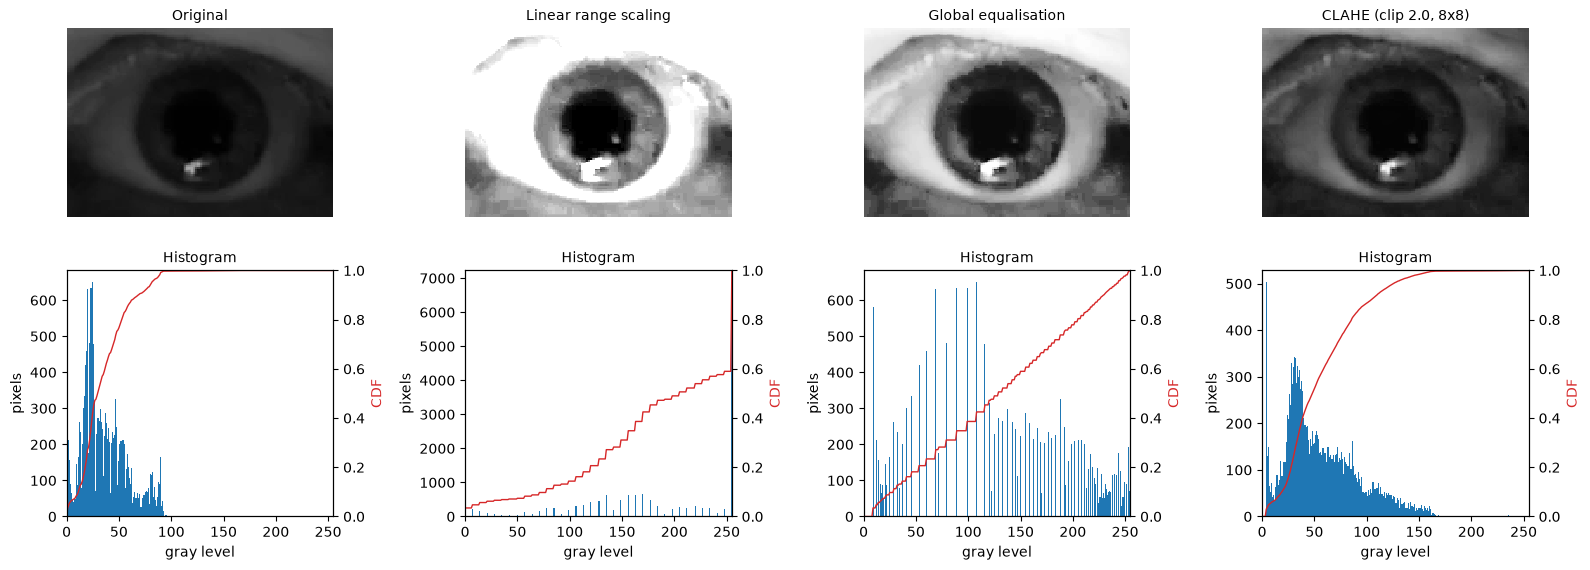

,mean,std,min,max,entropy_bits,clipped_%,laplacian_var
Original,35.560,22.433,0.000,168.000,6.125,0.006,24.183
Linear range scaling,185.406,76.584,0.000,255.000,3.839,44.466,463.646
Global equalisation,129.823,72.830,0.000,255.000,6.058,0.203,310.677
"CLAHE (clip 2.0, 8x8)",57.129,35.988,2.000,249.000,6.908,0.000,95.899


In [10]:
eq = I.equalize_global(gray)
clahe = I.equalize_clahe(gray, m1["clahe"]["clip_limit"], m1["clahe"]["tile_grid"])
enh = {"Original": gray, "Linear range scaling": scaled, "Global equalisation": eq,
       f"CLAHE (clip {m1['clahe']['clip_limit']}, {m1['clahe']['tile_grid']}x{m1['clahe']['tile_grid']})": clahe}

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for col, (name, img) in enumerate(enh.items()):
    axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, col].axis("off")
    axes[0, col].set_title(name, fontsize=10)
    plot_hist(axes[1, col], img, "Histogram")
    ax2 = axes[1, col].twinx(); ax2.plot(I.cdf_normalized(img), color="tab:red", lw=1); ax2.set_ylim(0, 1)
    ax2.set_ylabel("CDF", color="tab:red")
fig.tight_layout(); save_fig(fig, "m1_12_equalization", cfg); plt.show()

display(pd.DataFrame({k: {**M.describe(v), "laplacian_var": M.laplacian_variance(v)} for k, v in enh.items()}).T)

*`laplacian_var` grows when fine detail **and noise** are amplified: a very large value relative to the original points to
artefacts (grain in flat regions, halos around the reflections). Compare the sclera and the skin in each image.*

### 1.2.4 Noise models and spatial filtering

Three typical noises are simulated on the clean gray ROI (parameters in `config.yaml`), and each one is filtered with mean,
median and Gaussian filters. PSNR/SSIM are computed against the clean ROI.

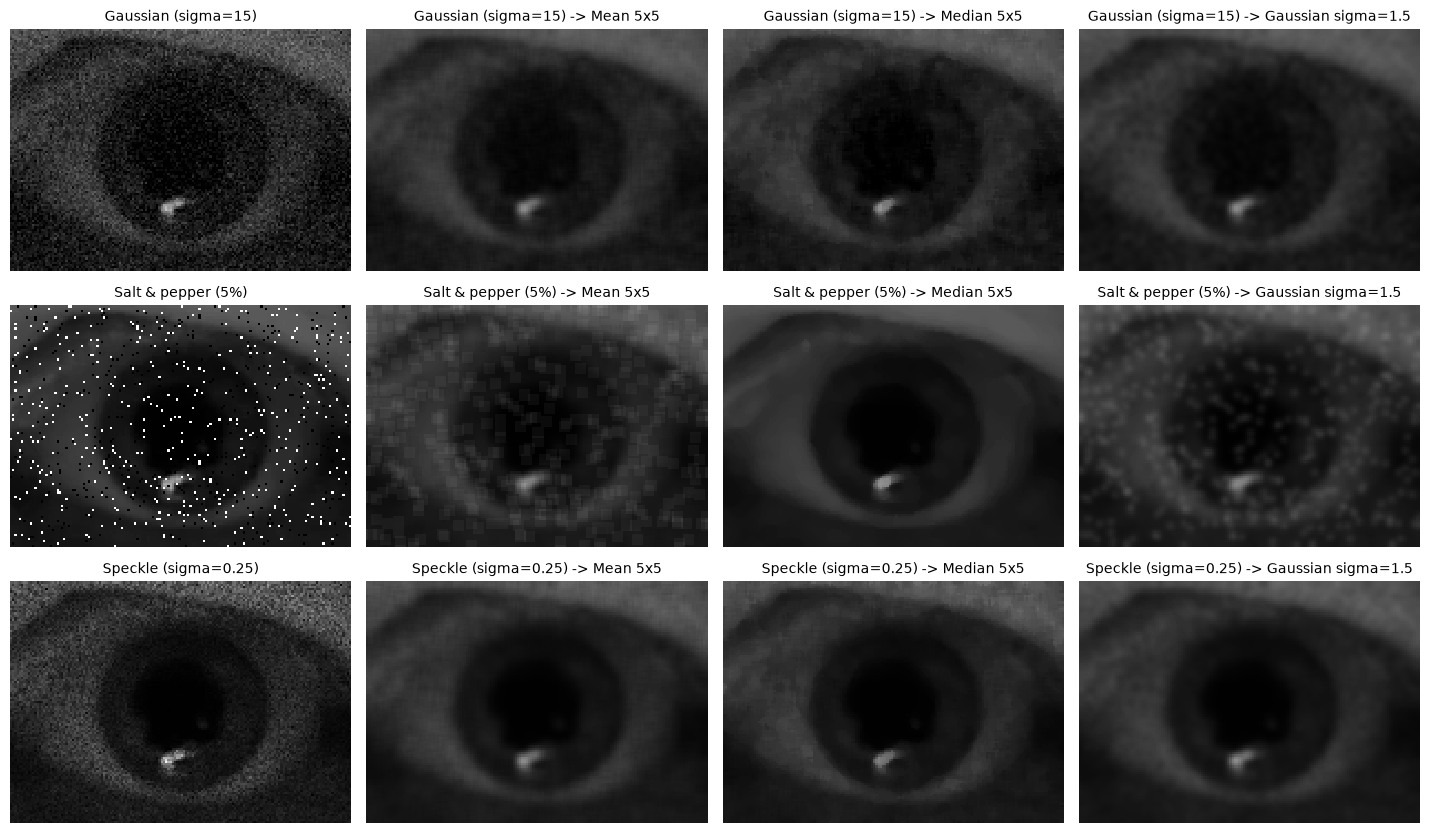

PSNR_dB  SSIM
noise                filter                           
Gaussian (sigma=15)  no filter            25.124 0.342
                     Mean 5x5             35.691 0.887
                     Median 5x5           34.937 0.863
                     Gaussian sigma=1.5   36.047 0.896
Salt & pepper (5%)   no filter            17.001 0.274
                     Mean 5x5             28.979 0.689
                     Median 5x5           40.959 0.984
                     Gaussian sigma=1.5   29.336 0.719
Speckle (sigma=0.25) no filter            27.772 0.627
                     Mean 5x5             37.526 0.950
                     Median 5x5           36.325 0.931
                     Gaussian sigma=1.5   37.906 0.956

Best filter per noise (by PSNR):


,best filter
noise,
Gaussian (sigma=15),Gaussian sigma=1.5
Salt & pepper (5%),Median 5x5
Speckle (sigma=0.25),Gaussian sigma=1.5


In [11]:
nz = m1["noise"]
noisy = {
    f"Gaussian (sigma={nz['gaussian_sigma']})": N.add_gaussian_noise(gray, nz["gaussian_sigma"], m1["seed"]),
    f"Salt & pepper ({nz['salt_pepper_amount']:.0%})": N.add_salt_pepper(gray, nz["salt_pepper_amount"], m1["seed"]),
    f"Speckle (sigma={nz['speckle_sigma']})": N.add_speckle(gray, nz["speckle_sigma"], m1["seed"]),
}
filters = {f"Mean {K}x{K}": lambda im: F.mean_filter(im, K),
           f"Median {K}x{K}": lambda im: F.median_filter(im, K),
           f"Gaussian sigma={SIGMA}": lambda im: F.gaussian_filter(im, SIGMA)}

images, titles, tables = [], [], {}
for nname, nimg in noisy.items():
    variants = {"no filter": nimg}
    for fname, fn in filters.items():
        variants[fname] = fn(nimg)
    tables[nname] = evaluate(f"noise: {nname}", gray, variants)
    images += list(variants.values())
    titles += [f"{nname}" if k == "no filter" else f"{nname} -> {k}" for k in variants]

fig = show_grid(images, titles, ncols=1 + len(filters), cell=(3.6, 2.8))
save_fig(fig, "m1_12_noise_filters", cfg); plt.show()

noise_table = pd.concat(tables, names=["noise", "filter"])
display(noise_table)
print("Best filter per noise (by PSNR):")
display(noise_table["PSNR_dB"].groupby(level="noise").idxmax().apply(lambda ix: ix[1]).to_frame("best filter"))

### 1.2.5 Filtering the flash reflection while keeping the pupil edge

The corneal reflection of the flash is *not* saturated in this kind of video (its gray level is similar to the sclera), so it cannot be
isolated with a global threshold. Here the three smoothing filters are compared with increasing kernel size on the **real** ROI:

* `edge_retention` = strength of the strongest edges after filtering / strength before (1.0 = edges fully preserved).
  It is a proxy dominated by the strongest contours (pupil/iris, eyelid, lashes), not an exact pupil-edge measure.
* PSNR / SSIM against the unfiltered ROI (they penalise removing the reflection as well, so read them together with the images).

For the Gaussian, the sigma equals the standard deviation of the box kernel (`k / sqrt(12)`), so all three filters blur by a comparable amount.

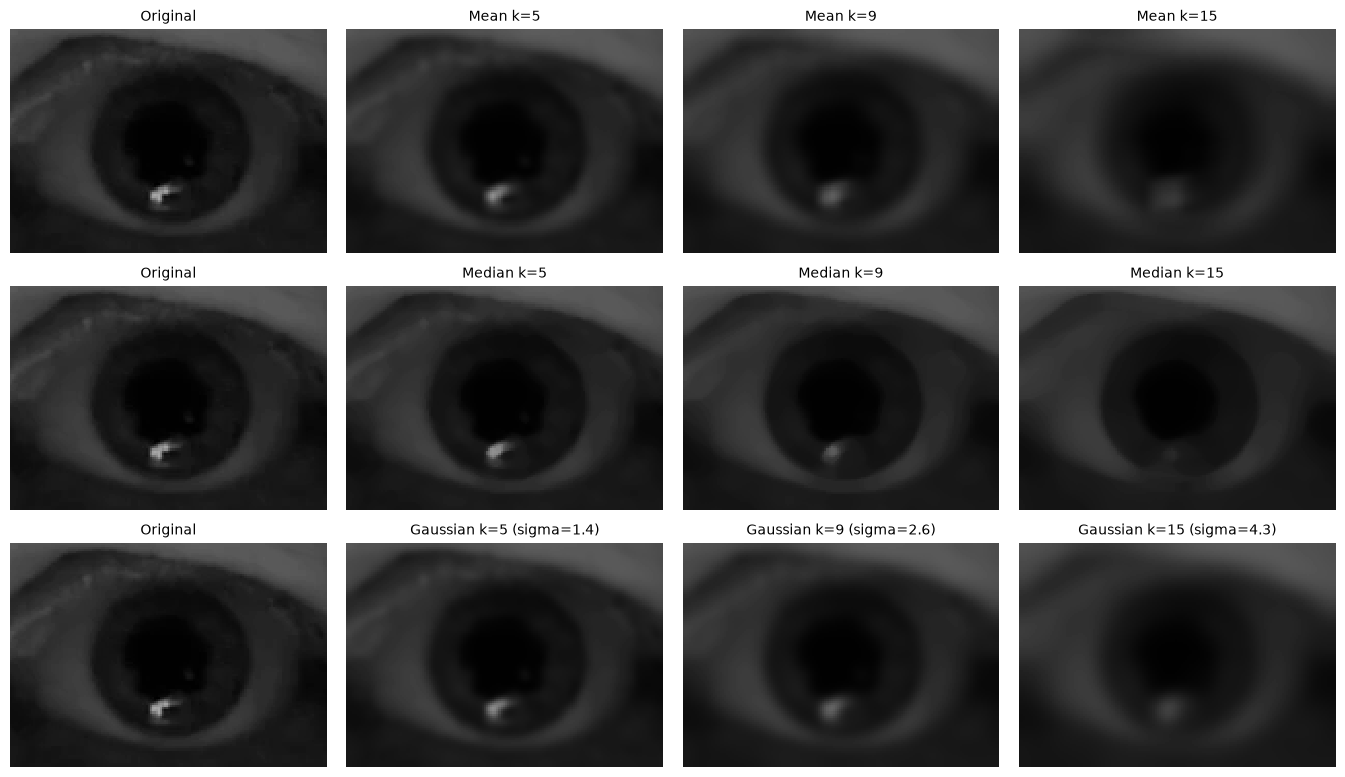

,PSNR_dB,SSIM,edge_retention
variant,,,
Mean k=5,39.433,0.976,0.726
Median k=5,41.367,0.986,0.883
Gaussian k=5 (sigma=1.4),40.157,0.979,0.732
Mean k=9,34.225,0.929,0.493
Median k=9,35.173,0.958,0.723
Gaussian k=9 (sigma=2.6),35.094,0.942,0.518
Mean k=15,30.602,0.851,0.317
Median k=15,31.469,0.914,0.601
Gaussian k=15 (sigma=4.3),31.546,0.880,0.337


In [12]:
kernels = m1["reflection_kernels"]
base_edge = M.edge_strength(gray)
variants = {}
for k in kernels:
    variants[f"Mean k={k}"] = F.mean_filter(gray, k)
    variants[f"Median k={k}"] = F.median_filter(gray, k)
    variants[f"Gaussian k={k} (sigma={k/np.sqrt(12):.1f})"] = F.gaussian_filter(gray, k / np.sqrt(12))

# one row per filter family, one column per kernel (first column: original)
order = ["Mean", "Median", "Gaussian"]
grid_imgs, grid_titles = [], []
for fam in order:
    grid_imgs.append(gray); grid_titles.append("Original")
    for name, img in variants.items():
        if name.startswith(fam):
            grid_imgs.append(img); grid_titles.append(name)
fig = show_grid(grid_imgs, grid_titles, ncols=1 + len(kernels), cell=(3.4, 2.6))
save_fig(fig, "m1_12_reflection_filters", cfg); plt.show()

tab = evaluate("reflection filters", gray, variants)
tab["edge_retention"] = [M.edge_strength(v) / base_edge for v in variants.values()]
tab

### 1.2.6 Spatial filters are not enough for large reflections

If the reflection is still visible after the largest kernel, that is expected: a smoothing filter only removes structures smaller than
its support. Removing the reflection from the pupil mask is done in **Module 2** with morphological operations (opening / closing
on the binary mask), where Dice / IoU against a manual annotation will quantify it.

## 1.3 Edge detection and frequency domain

### 1.3.1 Edge detection: Roberts, Sobel, Prewitt, Laplacian and Canny

Applied on the original and on the pre-filtered gray ROI (`edges.prefilter` in `config.yaml`).
Gradient operators are binarised keeping the strongest `100 - percentile` % of pixels, so all of them have the same edge density
and can be compared; Canny uses its own hysteresis thresholds.

*Contour continuity* is measured on the 1-pixel skeleton of each binary map: **fewer, longer connected components = more
continuous contours** (`largest_fraction` = share of the edge pixels that belong to the longest connected contour).

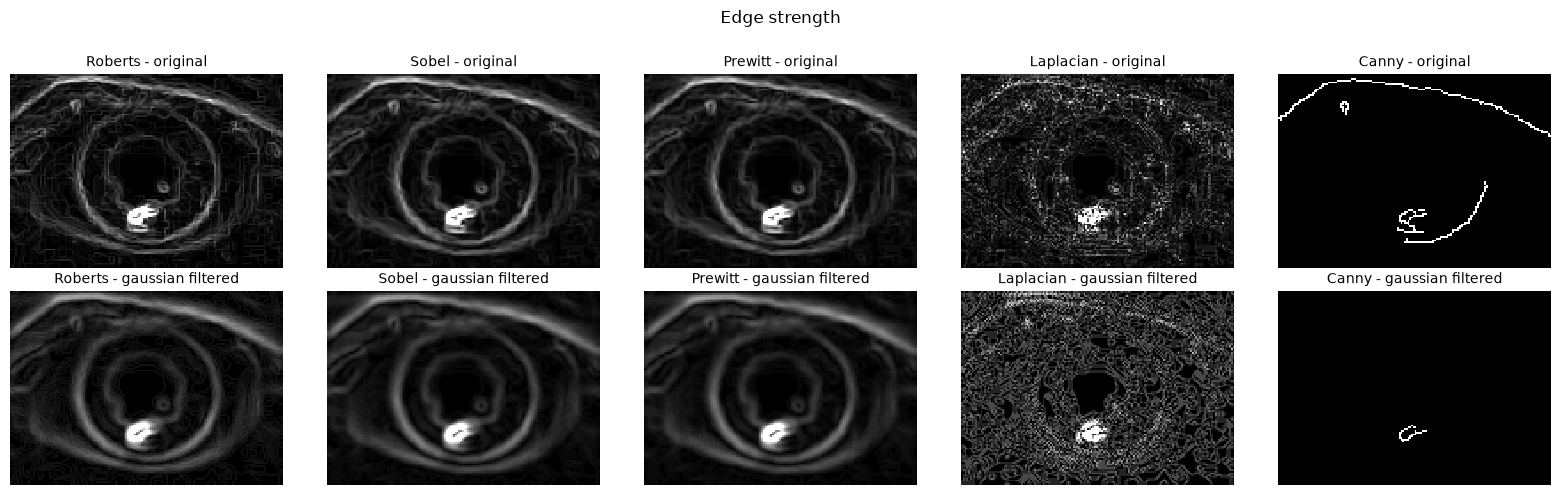

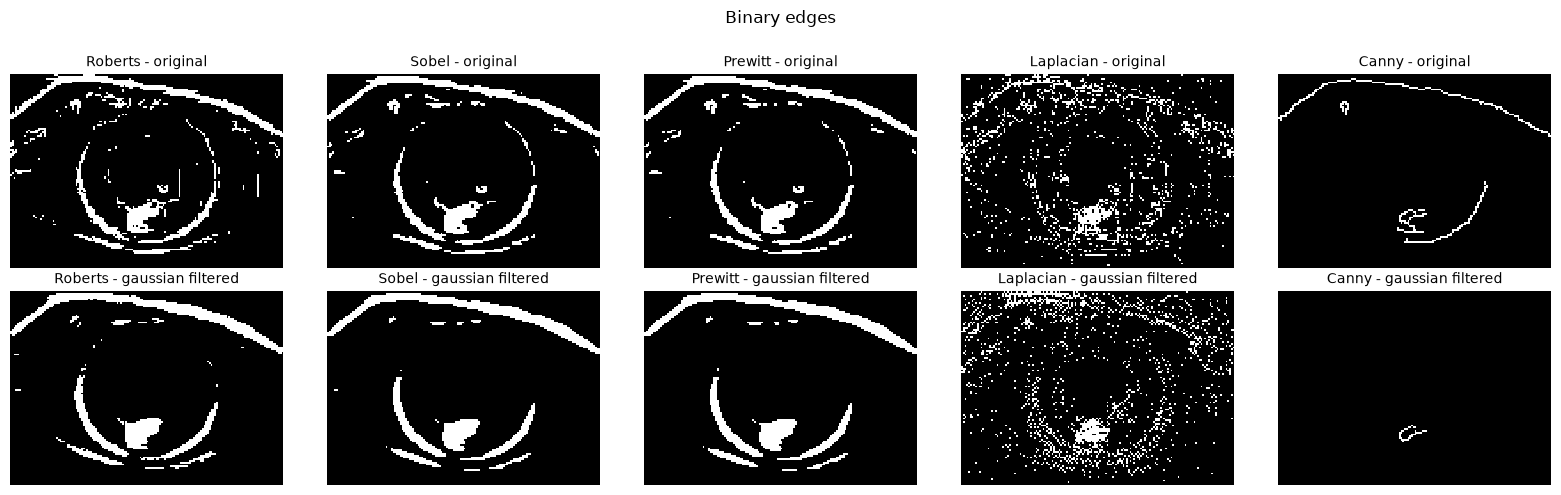

edge_px  n_components  largest_px  largest_fraction
operator  input                                                            
Roberts   original          748            84         171             0.229
          pre-filtered      424            24         151             0.356
Sobel     original          546            39         158             0.289
          pre-filtered      368            15         152             0.413
Prewitt   original          530            38         155             0.292
          pre-filtered      368            14         152             0.413
Laplacian original         1341           476         154             0.115
          pre-filtered     1476           576         138             0.093
Canny     original          279             5         154             0.552
          pre-filtered       28             1          28             1.000

In [13]:
pre = F.apply_named_filter(gray, m1["edges"]["prefilter"], k=K, sigma=SIGMA)
e = m1["edges"]

def all_edges(img):
    maps = E.gradient_maps(img)
    bins = {name: E.binarize(m, e["percentile"]) for name, m in maps.items()}
    bins["Canny"] = E.canny(img, e["canny"]["low"], e["canny"]["high"])
    maps["Canny"] = bins["Canny"].astype(float)
    return maps, bins

maps_o, bins_o = all_edges(gray)
maps_f, bins_f = all_edges(pre)
ops = list(maps_o)

for label, a, b, fname in (("Edge strength", maps_o, maps_f, "m1_13_edge_strength"),
                           ("Binary edges", {k: v.astype(np.uint8) * 255 for k, v in bins_o.items()},
                            {k: v.astype(np.uint8) * 255 for k, v in bins_f.items()}, "m1_13_edge_binary")):
    imgs = [a[k] for k in ops] + [b[k] for k in ops]
    ttl = [f"{k} - original" for k in ops] + [f"{k} - {m1['edges']['prefilter']} filtered" for k in ops]
    fig = show_grid(imgs, ttl, ncols=len(ops), cell=(3.2, 2.5), suptitle=label,
                    vmin=0 if imgs[0].dtype != np.uint8 else None, vmax=1 if imgs[0].dtype != np.uint8 else None)
    save_fig(fig, fname, cfg); plt.show()

rows = []
for k in ops:
    for src, bins in (("original", bins_o), ("pre-filtered", bins_f)):
        rows.append({"operator": k, "input": src, **E.edge_continuity(bins[k])})
display(pd.DataFrame(rows).set_index(["operator", "input"]))

### 1.3.2 2-D DFT: magnitude, phase and reconstructions

* Magnitude is shown in logarithmic scale, phase in radians.
* Reconstructions: magnitude only (phase = 0), phase only (magnitude = 1) and **crossed** (magnitude of one frame with the phase
  of the other). Frame 1 and frame 2 use the same ROI box.

Round-trip error (DFT -> inverse DFT): 1.1368683772161603e-13


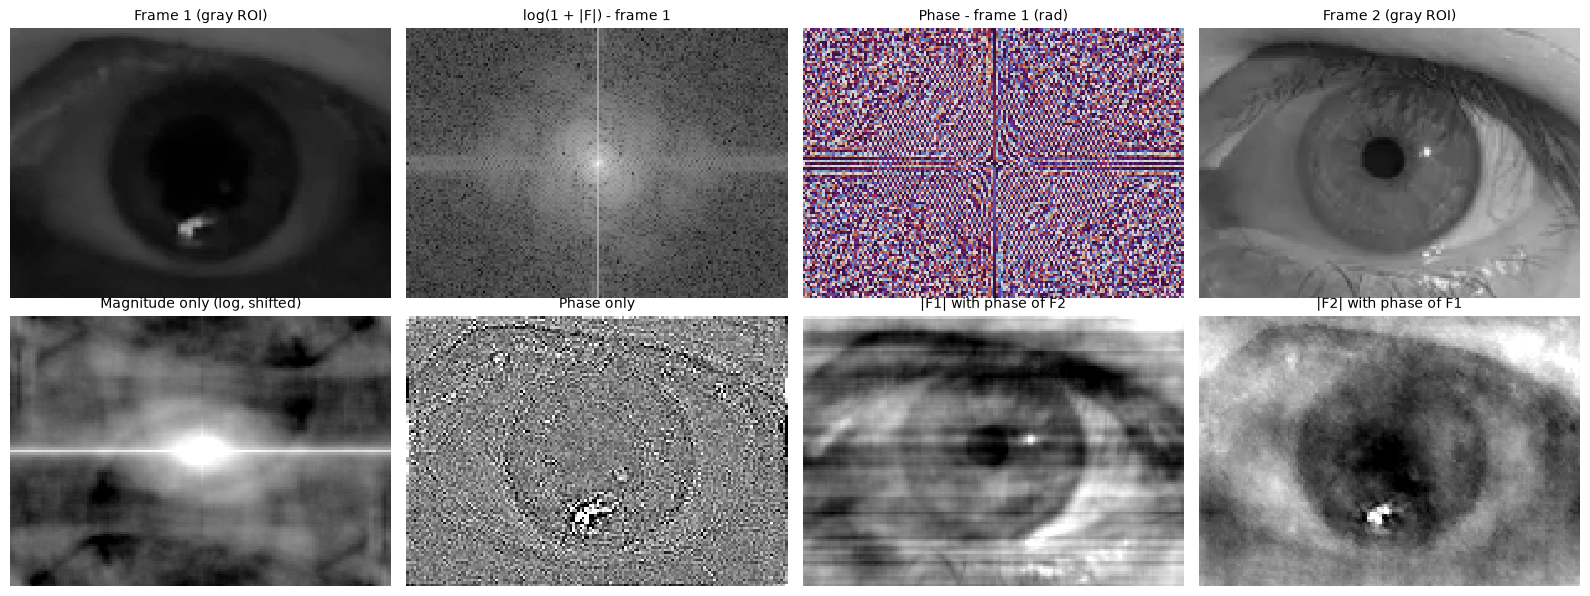

In [14]:
Fa, Fb = Q.fft2c(gray), Q.fft2c(gray2)
print("Round-trip error (DFT -> inverse DFT):", np.abs(Q.ifft2c(Fa) - gray).max())

rec_mag = Q.recon_magnitude_only(Fa)
rec_pha = Q.recon_phase_only(Fa)
cross_ab = Q.recon_cross(Fa, Fb)   # magnitude of frame 1 + phase of frame 2
cross_ba = Q.recon_cross(Fb, Fa)   # magnitude of frame 2 + phase of frame 1

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
panels = [
    (gray, "Frame 1 (gray ROI)", "gray", (0, 255)),
    (Q.log_magnitude(Fa), "log(1 + |F|) - frame 1", "gray", (None, None)),
    (Q.phase(Fa), "Phase - frame 1 (rad)", "twilight", (-np.pi, np.pi)),
    (gray2, "Frame 2 (gray ROI)", "gray", (0, 255)),
    (norm_display(np.log1p(np.abs(np.fft.fftshift(rec_mag)))), "Magnitude only (log, shifted)", "gray", (0, 255)),
    (norm_display(rec_pha), "Phase only", "gray", (0, 255)),
    (norm_display(cross_ab), "|F1| with phase of F2", "gray", (0, 255)),
    (norm_display(cross_ba), "|F2| with phase of F1", "gray", (0, 255)),
]
for ax, (img, title, cmap, (lo, hi)) in zip(axes.ravel(), panels):
    ax.imshow(img, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(title, fontsize=10); ax.axis("off")
fig.tight_layout(); save_fig(fig, "m1_13_dft_reconstructions", cfg); plt.show()

*Which one keeps the structure (edges, pupil outline, eyelid)? Compare each crossed reconstruction with frame 1 and frame 2:
the image that "wins" tells you whether structure lives in the magnitude or in the phase.*

### 1.3.3 Power spectral density (PSD) before and after spatial filtering

PSD = |F|^2 (mean removed, Hann window against edge leakage). The radial average shows how much power survives at each spatial
frequency (cycles/pixel; 0.5 is the Nyquist limit).

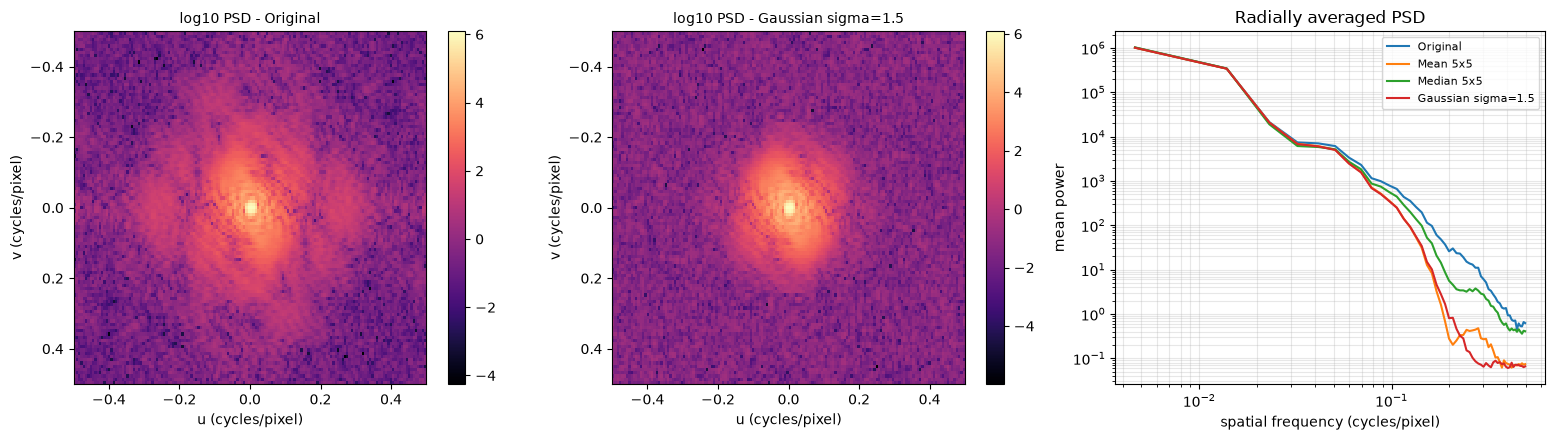

In [15]:
psd_inputs = {"Original": gray,
              f"Mean {K}x{K}": F.mean_filter(gray, K),
              f"Median {K}x{K}": F.median_filter(gray, K),
              f"Gaussian sigma={SIGMA}": F.gaussian_filter(gray, SIGMA)}
psds = {k: Q.psd2d(v) for k, v in psd_inputs.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes[:2], ("Original", f"Gaussian sigma={SIGMA}")):
    im = ax.imshow(np.log10(psds[name] + 1e-12), cmap="magma", extent=[-0.5, 0.5, 0.5, -0.5])
    ax.set_title(f"log10 PSD - {name}", fontsize=10)
    ax.set_xlabel("u (cycles/pixel)"); ax.set_ylabel("v (cycles/pixel)")
    fig.colorbar(im, ax=ax, fraction=0.046)
for name, P in psds.items():
    fr, pr = Q.radial_profile(P)
    axes[2].loglog(fr, pr, label=name)
axes[2].set_xlabel("spatial frequency (cycles/pixel)"); axes[2].set_ylabel("mean power")
axes[2].set_title("Radially averaged PSD"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3, which="both")
fig.tight_layout(); save_fig(fig, "m1_13_psd", cfg); plt.show()

### 1.3.4 Frequency-domain filtering and comparison with spatial filtering

Low-pass and high-pass filters (ideal, Gaussian, Butterworth) with the cut-off `frequency.cutoff` (cycles/pixel).
The ideal filter produces *ringing* (Gibbs) because its sharp cut-off is a sinc in the spatial domain.
A Gaussian low-pass in frequency with `H = exp(-2 pi^2 sigma^2 (u^2 + v^2))` is exactly the transfer function of a spatial Gaussian
of standard deviation `sigma`, which is verified numerically below.

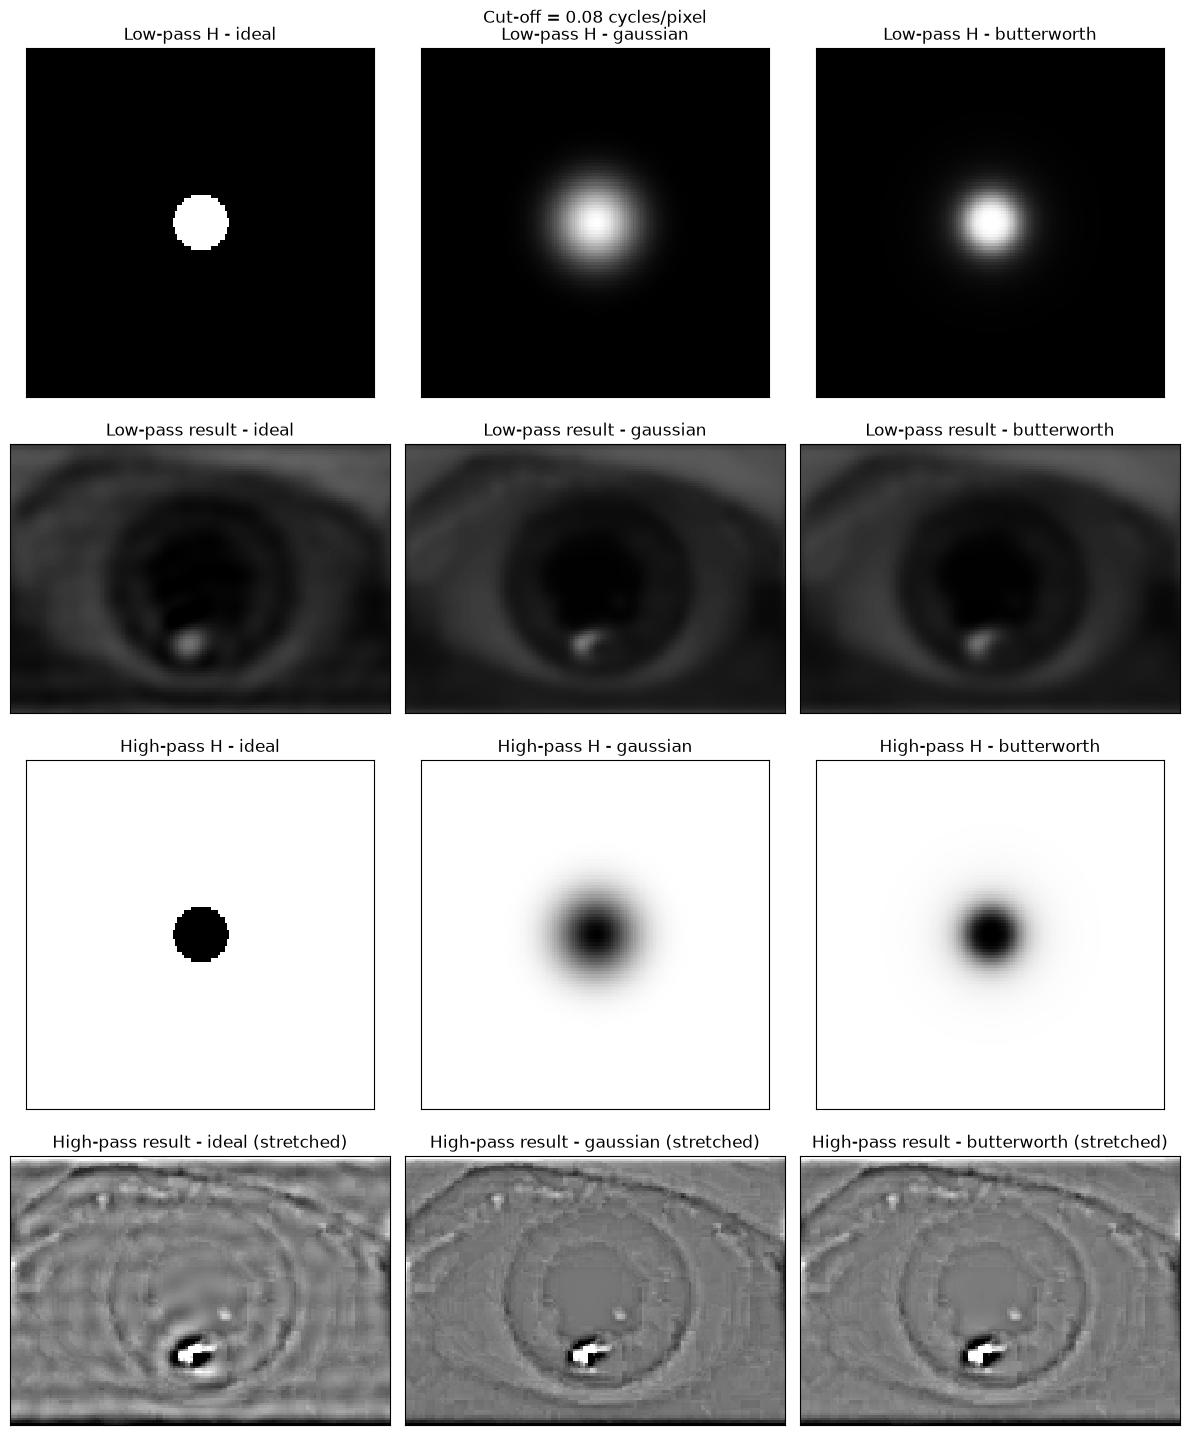

Spatial Gaussian (sigma=1.5) vs frequency-domain equivalent: PSNR = 37.7 dB (differences come from the image borders: periodic extension in the DFT vs reflection in the spatial filter)


,PSNR_dB,SSIM
variant,,
Low-pass ideal (fc=0.08),31.602,0.881
Low-pass gaussian (fc=0.08),33.482,0.946
Low-pass butterworth (fc=0.08),32.700,0.929


In [16]:
fq = m1["frequency"]
fc, order = fq["cutoff"], fq["butterworth_order"]
kinds = ["ideal", "gaussian", "butterworth"]
H_lp = {k: Q.lowpass_filter(gray.shape, fc, k, order) for k in kinds}
H_hp = {k: Q.highpass_filter(gray.shape, fc, k, order) for k in kinds}
lp = {k: Q.apply_freq_filter(gray, H_lp[k]) for k in kinds}
hp = {k: Q.apply_freq_filter(gray, H_hp[k]) for k in kinds}

fig, axes = plt.subplots(4, 3, figsize=(12, 15))
for col, k in enumerate(kinds):
    axes[0, col].imshow(H_lp[k], cmap="gray", extent=[-0.5, 0.5, 0.5, -0.5]); axes[0, col].set_title(f"Low-pass H - {k}")
    axes[1, col].imshow(to_uint8(lp[k]), cmap="gray", vmin=0, vmax=255); axes[1, col].set_title(f"Low-pass result - {k}")
    axes[2, col].imshow(H_hp[k], cmap="gray", extent=[-0.5, 0.5, 0.5, -0.5]); axes[2, col].set_title(f"High-pass H - {k}")
    axes[3, col].imshow(norm_display(hp[k]), cmap="gray", vmin=0, vmax=255); axes[3, col].set_title(f"High-pass result - {k} (stretched)")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Cut-off = {fc} cycles/pixel", fontsize=12)
fig.tight_layout(); save_fig(fig, "m1_13_frequency_filters", cfg); plt.show()

# Spatial Gaussian vs its frequency-domain equivalent
spatial = F.gaussian_filter(gray, SIGMA)
freq_eq = to_uint8(Q.apply_freq_filter(gray, Q.gaussian_lowpass_from_sigma(gray.shape, SIGMA)))
print(f"Spatial Gaussian (sigma={SIGMA}) vs frequency-domain equivalent: PSNR = {M.psnr(spatial, freq_eq):.1f} dB "
      "(differences come from the image borders: periodic extension in the DFT vs reflection in the spatial filter)")

display(evaluate("frequency low-pass", gray, {f"Low-pass {k} (fc={fc})": to_uint8(lp[k]) for k in kinds}))

## 1.4 Quality metrics summary (PSNR / SSIM)

* **PSNR** = 10 log10(255^2 / MSE): pixel-wise error in dB (higher is better; infinite if identical). It ignores *where* the error is.
* **SSIM** compares local luminance, contrast and structure in 7x7 windows (1 = identical). It is closer to perceived degradation.

Both are *full-reference* metrics: they need the original image as reference.

In [17]:
summary = pd.DataFrame(metrics_rows).set_index(["group", "variant"])
summary.to_csv(cfg["_output_dir"] / "module1_metrics.csv")
display(summary)
print("Saved:", cfg["_output_dir"] / "module1_metrics.csv")

PSNR_dB  SSIM
group                       variant                                      
downsampling (RGB)          50 %                             42.988 0.987
                            25 %                             36.861 0.955
                            5 %                              26.462 0.720
quantization (RGB)          RGB 4 bit                        31.091 0.763
                            RGB 2 bit                        18.283 0.159
quantization (gray)         gray 4 bit                       31.176 0.802
                            gray 2 bit                       18.138 0.129
brightness / contrast       Brightness +50                   14.151 0.629
                            Contrast x1.5                    21.675 0.893
noise: Gaussian (sigma=15)  no filter                        25.124 0.342
                            Mean 5x5                         35.691 0.887
                            Median 5x5                       34.937 0.863
                            Gaussian sigma=1.5               36.047 0.896
noise: Salt & pepper (5%)   no filter                        17.001 0.274
                            Mean 5x5                         28.979 0.689
                            Median 5x5                       40.959 0.984
                            Gaussian sigma=1.5               29.336 0.719
noise: Speckle (sigma=0.25) no filter                        27.772 0.627
                            Mean 5x5                         37.526 0.950
                            Median 5x5                       36.325 0.931
                            Gaussian sigma=1.5               37.906 0.956
reflection filters          Mean k=5                         39.433 0.976
                            Median k=5                       41.367 0.986
                            Gaussian k=5 (sigma=1.4)         40.157 0.979
                            Mean k=9                         34.225 0.929
                            Median k=9                       35.173 0.958
                            Gaussian k=9 (sigma=2.6)         35.094 0.942
                            Mean k=15                        30.602 0.851
                            Median k=15                      31.469 0.914
                            Gaussian k=15 (sigma=4.3)        31.546 0.880
frequency low-pass          Low-pass ideal (fc=0.08)         31.602 0.881
                            Low-pass gaussian (fc=0.08)      33.482 0.946
                            Low-pass butterworth (fc=0.08)   32.700 0.929

Saved: /home/zenith/Documents/PSIB/Competencia/psib-pupilometry/results/gui_validation/roi_True_cal_False/module1_metrics.csv


## 1.5 Guide questions - answer with your own results

**Q1. Which filter best preserves the pupil edges while removing the flash reflections?**
Use the images of 1.2.4-1.2.5, `edge_retention`, the continuity table of 1.3.1 and the PSD of 1.3.3.
Does the reflection disappear for any kernel size? What does that tell you about Module 2?

> *Write your conclusion here.*

**Q2. How can the quality of an image be quantified against the original?**
Full-reference metrics (PSNR, SSIM) are in section 1.4. Which filter / noise combination gave the best and worst values, and do PSNR and SSIM agree?

> *Write your conclusion here.*

**Q3. Which representation carries the structure: magnitude or phase?** (1.3.2)

> *Write your conclusion here.*

**Q4. Spatial vs frequency-domain filtering:** when is each one preferable? (1.3.4)

> *Write your conclusion here.*